In [3]:

#  IMPORT LIBRARIES


!pip install -q xgboost shap imbalanced-learn scikit-optimize openpyxl

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
    RandomizedSearchCV
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_squared_error
)

from xgboost import XGBRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [4]:

#  LOAD DATA

from google.colab import files

uploaded = files.upload()

df_raw = pd.read_excel(next(iter(uploaded)))

print(df_raw.shape)
df_raw.head()
# Summary statistics
df_raw.describe(include='all')

Saving Vehicles_final (1).xlsx to Vehicles_final (1).xlsx
(797, 10)


,Vehicle_Title,Price,Year,Engine_CC,Transmission,Mileage,Condition,Make,Model,County
count,797,7.920000e+02,796.000000,659.000000,170,7.970000e+02,691,797,797,797
unique,279,NaN,NaN,NaN,6,NaN,4,21,279,5
top,Toyota Land Cruiser Prado,NaN,NaN,NaN,Automatic,NaN,Foreign Used,Toyota,Land Cruiser Prado,Nairobi
freq,136,NaN,NaN,NaN,137,NaN,421,363,136,776
mean,NaN,6.007379e+06,2015.429648,2783.778452,NaN,1.009345e+05,NaN,NaN,NaN,NaN
std,NaN,4.506526e+06,3.667477,810.964651,NaN,1.946592e+05,NaN,NaN,NaN,NaN
min,NaN,2.015000e+03,1998.000000,0.000000,NaN,1.000000e+00,NaN,NaN,NaN,NaN
25%,NaN,3.200000e+06,2014.000000,2800.000000,NaN,4.300000e+04,NaN,NaN,NaN,NaN
50%,NaN,5.300000e+06,2016.000000,3000.000000,NaN,5.600000e+04,NaN,NaN,NaN,NaN
75%,NaN,7.799999e+06,2018.000000,3000.000000,NaN,8.900000e+04,NaN,NaN,NaN,NaN



 Missing values
Transmission     627
Engine_CC        138
Condition        106
Price              5
Year               1
Vehicle_Title      0
Mileage            0
Make               0
Model              0
County             0
dtype: int64


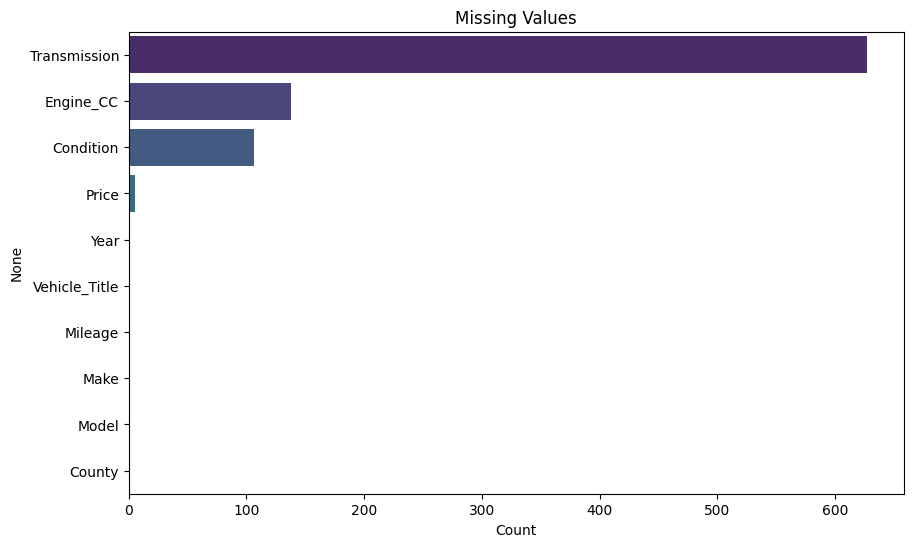

In [5]:
print("\n Missing values")
missing = df_raw.isnull().sum().sort_values(ascending=False)
print(missing)

plt.figure(figsize=(10,6))
sns.barplot(
    x=missing.values,
    y=missing.index,
    palette="viridis"
)

plt.title("Missing Values")
plt.xlabel("Count")
plt.show()

In [6]:

print("Duplicate Rows:", df_raw.duplicated().sum())

Duplicate Rows: 0


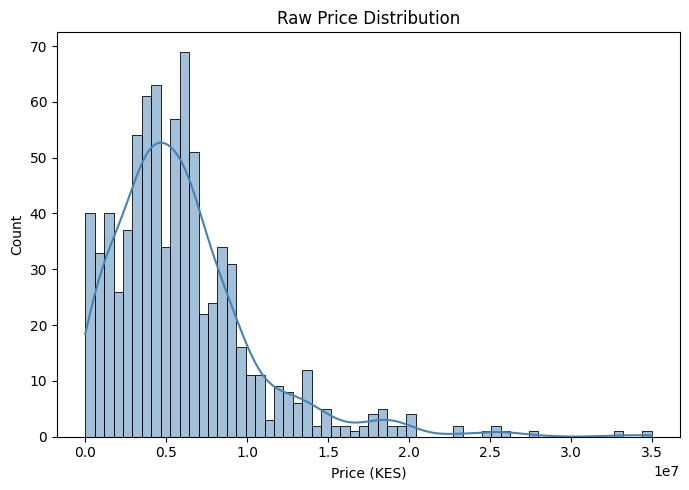

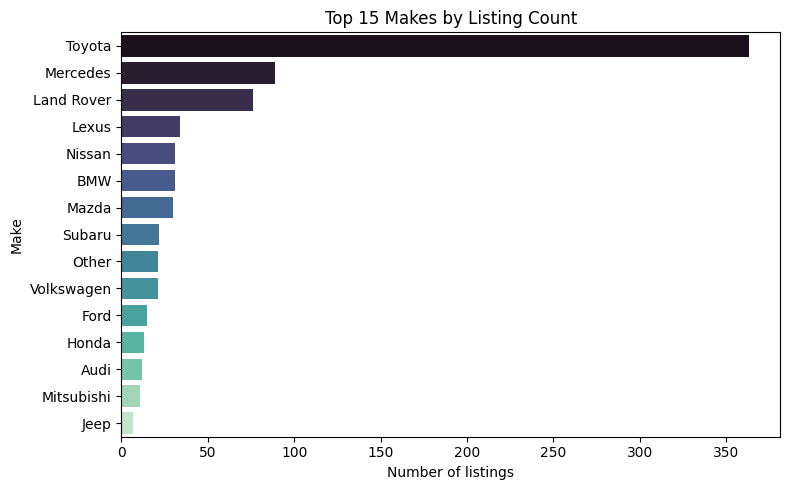

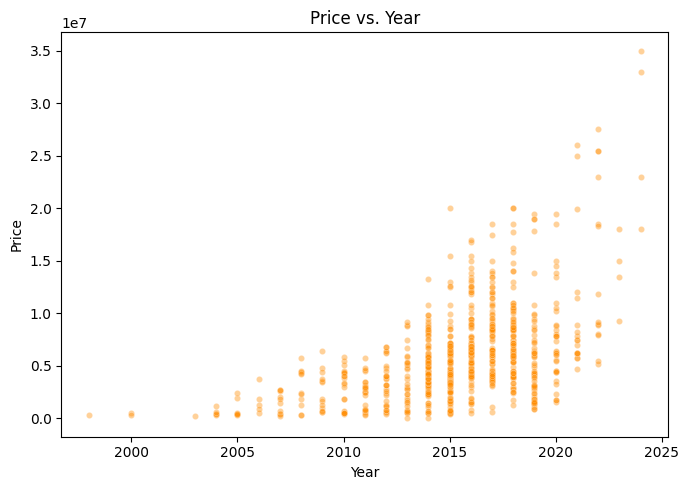

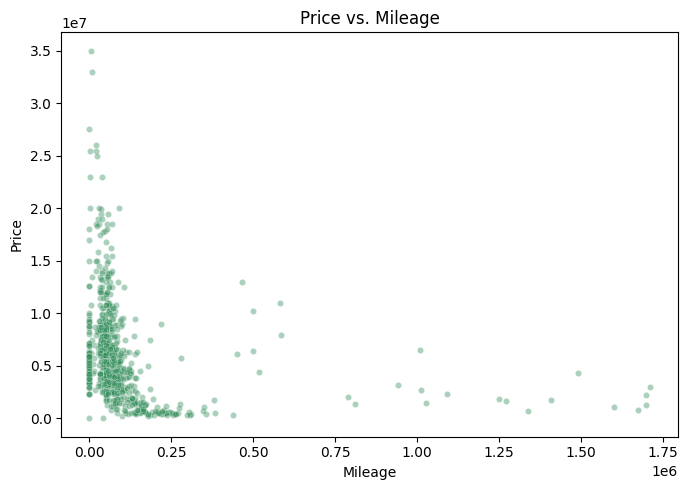

In [16]:
# Price distribution (raw)
import os
import pathlib

FIG_DIR = "plots"
pathlib.Path(FIG_DIR).mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(7, 5))
sns.histplot(df_raw["Price"].dropna(), bins=60, kde=True, color="steelblue")
plt.title("Raw Price Distribution")
plt.xlabel("Price (KES)")
plt.tight_layout()

plt.show()

# Top makes by listing count
plt.figure(figsize=(8, 5))
top_makes = df_raw["Make"].value_counts().head(15)
sns.barplot(x=top_makes.values, y=top_makes.index, palette="mako")
plt.xlabel("Number of listings")
plt.title("Top 15 Makes by Listing Count")
plt.tight_layout()

plt.show()

# Price vs Year
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_raw, x="Year", y="Price", alpha=0.4, s=20, color="darkorange")
plt.title("Price vs. Year")
plt.tight_layout()

plt.show()


# Price vs Mileage
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_raw, x="Mileage", y="Price", alpha=0.4, s=20, color="seagreen")
plt.title("Price vs. Mileage")
plt.tight_layout()

plt.show()

In [10]:

# DATA CLEANING
import os
import pathlib

OUT_DIR = "output"
pathlib.Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

df = df_raw.copy()

df = df.dropna(subset=["Price","Make","Model","Year"])

# Fill Engine_CC
n_zero_cc = (df["Engine_CC"] == 0).sum()
df["Engine_CC"] = df["Engine_CC"].replace(0, np.nan)
print(f"Engine_CC: treated {n_zero_cc} zero values as missing.")

engine_group = df.groupby(["Make","Model"])["Engine_CC"].transform("median")
engine_make = df.groupby("Make")["Engine_CC"].transform("median")

df["Engine_CC"] = (
    df["Engine_CC"]
    .fillna(engine_group)
    .fillna(engine_make)
    .fillna(df["Engine_CC"].median())
)

PRICE_UPPER_LIMIT = 10_000_000

df.loc[df["Price"] > PRICE_UPPER_LIMIT, ["Vehicle_Title","Make","Model","Year","Price"]] \
  .to_csv(f"{OUT_DIR}/suspect_price_over_10m_review.csv", index=False)

df = df[df["Price"] <= PRICE_UPPER_LIMIT]

log_price = np.log1p(df["Price"])
q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = np.expm1(q1 - 1.5 * iqr), np.expm1(q3 + 1.5 * iqr)

df = df[(df["Price"] >= lower) & (df["Price"] <= upper)]

df["Condition"] = df["Condition"].str.strip()
df["Condition"] = df["Condition"].replace({"Local Used": "Locally Used"})
df["Condition"] = df["Condition"].fillna(df["Condition"].mode()[0])

CURRENT_YEAR = 2026

df["Car_Age"] = CURRENT_YEAR - df["Year"]
df["Mileage_Per_Year"] = df["Mileage"] / df["Car_Age"].replace(0,1)

df["Log_Price"] = np.log1p(df["Price"])
df["Log_Mileage"] = np.log1p(df["Mileage"])

Engine_CC: treated 7 zero values as missing.


In [14]:
# FEATURE ENGINEERING

df["MakeModel"] = df["Make"] + "_" + df["Model"]

train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)

def kfold_target_encode(train, test, column, target, n_splits=5, seed=RANDOM_STATE):
    train = train.copy()
    test = test.copy()
    global_mean = train[target].mean()

    oof = pd.Series(index=train.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr_idx, val_idx in kf.split(train):
        fold_means = train.iloc[tr_idx].groupby(column)[target].mean()
        oof.iloc[val_idx] = train.iloc[val_idx][column].map(fold_means)
    train[column + "_TE"] = oof.fillna(global_mean)

    full_means = train.groupby(column)[target].mean()
    test[column + "_TE"] = test[column].map(full_means).fillna(global_mean)

    return train, test

train_df, test_df = kfold_target_encode(train_df, test_df, "MakeModel", "Price")

NUMERIC = [
    "Car_Age",
    "Log_Mileage",
    "Mileage_Per_Year",
    "Engine_CC",
    "MakeModel_TE"
]

CATEGORICAL = [
    "Condition",
    "County"
]

for col in CATEGORICAL:
    train_df[col] = train_df[col].fillna("Unknown")
    test_df[col] = test_df[col].fillna("Unknown")

X_train = train_df[NUMERIC + CATEGORICAL]
X_test = test_df[NUMERIC + CATEGORICAL]
y_train = train_df["Log_Price"]
y_test = test_df["Log_Price"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", "passthrough", NUMERIC)
])

In [15]:
# LINEAR REGRESSION


mlr = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression())
])

mlr.fit(X_train, y_train)

pred_lr = mlr.predict(X_test)

rmse_lr = np.sqrt(
    mean_squared_error(
        np.expm1(y_test),
        np.expm1(pred_lr)
    )
)

print("Linear Regression RMSE:", rmse_lr)

Linear Regression RMSE: 1456644.3032893934
